# AnomaForge — Stage 1: Explore the MVTec AD `bottle` dataset

**Goal:** Confirm our dataset paths, inspect normal and defective sample images, view a real matching ground-truth defect mask, and check the planned **224 × 224** model-input shape.


## 1. Mount Google Drive

Upload/extract the official MVTec AD `bottle` folder from Drive before running the remaining cells.

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Pointing the notebook to the extracted bottle folder

The  folder should directly contain the `train/`, `test/`, and `ground_truth/` directories. Edit the path if necessary according to your drive path guys

In [20]:
from pathlib import Path

# edit this if you extracted the bottle folder somewhere else.
BOTTLE_DIR = Path('/content/drive/MyDrive/ANOMAFORGE/Bottle')

required = ['train/good', 'test/good', 'ground_truth']
missing = [x for x in required if not (BOTTLE_DIR / x).is_dir()]
if missing:
    raise FileNotFoundError(
        f"Could not find the expected folders under {BOTTLE_DIR}.\n"
        f"Missing: {missing}\n"
        "Extract the official 'bottle' category into Drive and update BOTTLE_DIR."
    )
print('Dataset folder found:', BOTTLE_DIR)

Dataset folder found: /content/drive/MyDrive/ANOMAFORGE/Bottle


## 3. Count images and inspect the available labels

The training split should consist of normal images. The test split contains normal images and actual defects. We do not use real defect masks to train our models.

In [21]:
def image_files(folder):
    return sorted(p for p in folder.glob('*.png') if p.is_file())

print('Training categories:')
for folder in sorted((BOTTLE_DIR / 'train').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s} : {len(image_files(folder))} images')

print('\nTest categories:')
for folder in sorted((BOTTLE_DIR / 'test').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s} : {len(image_files(folder))} images')

print('\nGround-truth mask categories:')
for folder in sorted((BOTTLE_DIR / 'ground_truth').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s} : {len(image_files(folder))} masks')

Training categories:
  good               : 209 images

Test categories:
  broken_large       : 20 images
  broken_small       : 22 images
  contamination      : 21 images
  good               : 20 images

Ground-truth mask categories:
  broken_large       : 20 masks
  broken_small       : 22 masks
  contamination      : 21 masks


## 4. Visualizing one normal image and one real defective image

The official MVTec AD naming convention pairs a defective image such as `002.png` with a mask named `002_mask.png` inside the matching `ground_truth/<defect_type>/` folder. Wrote this as a dataset-inspection step

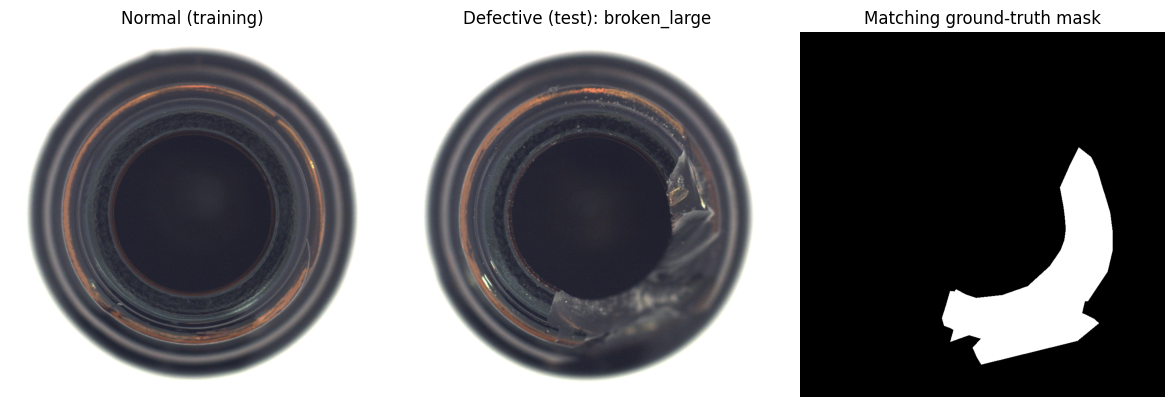

Normal image: 000.png (900, 900)
Defective image: 000.png (900, 900)
Mask: 000_mask.png (900, 900)


In [22]:
from PIL import Image
import matplotlib.pyplot as plt

normal_paths = image_files(BOTTLE_DIR / 'train' / 'good')
assert normal_paths, 'No normal training images were found.'
normal_path = normal_paths[0]

defect_types = [p.name for p in (BOTTLE_DIR / 'test').iterdir()
                if p.is_dir() and p.name != 'good' and image_files(p)]
assert defect_types, 'No defective test images were found.'
defect_type = sorted(defect_types)[0]
defect_path = image_files(BOTTLE_DIR / 'test' / defect_type)[0]
mask_path = BOTTLE_DIR / 'ground_truth' / defect_type / f'{defect_path.stem}_mask.png'
if not mask_path.is_file():
    raise FileNotFoundError(f'Expected matching defect mask was not found: {mask_path}')

normal = Image.open(normal_path).convert('RGB')
defective = Image.open(defect_path).convert('RGB')
mask = Image.open(mask_path).convert('L')

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(normal);    axes[0].set_title('Normal (training)')
axes[1].imshow(defective); axes[1].set_title(f'Defective (test): {defect_type}')
axes[2].imshow(mask, cmap='gray', vmin=0, vmax=255); axes[2].set_title('Matching ground-truth mask')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print('Normal image:', normal_path.name, normal.size)
print('Defective image:', defect_path.name, defective.size)
print('Mask:', mask_path.name, mask.size)

## 5. Check the planned neural-network input size

Our later DINOv3 and Student CNN stages will use **224 × 224 RGB** images. Here we check only shape and pixel range.

In [23]:
import numpy as np
import torch

resized = normal.resize((224, 224), Image.Resampling.BILINEAR)
array = np.asarray(resized, dtype=np.float32) / 255.0
tensor = torch.from_numpy(array).permute(2, 0, 1).contiguous()

print('Prepared input tensor shape:', tuple(tensor.shape))
print('Pixel range:', float(tensor.min()), 'to', float(tensor.max()))
assert tuple(tensor.shape) == (3, 224, 224)
print('Stage 1 tensor check passed.')

Prepared input tensor shape: (3, 224, 224)
Pixel range: 0.12156862765550613 to 1.0
Stage 1 tensor check passed.


---
## Stage 2 - Frozen DINOv3 teacher features

1. Get access to [Meta's DINOv3 ViT-S/16 checkpoint](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m).


We reuse the `normal` PIL image loaded in Stage 1, but run DINOv3's own preprocessing inside `teacher.py`.

In [24]:
%pip install -q "transformers==5.21.0" "huggingface-hub==1.32.0"

In [25]:

# Stage 2B: Load teacher.py from Kshitija's branch

import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ANN-PROJECT-26/ANOMAFORGE.git"

# No slash at the beginning
BRANCH = "feature/kshitija"

# Separate folder for your branch
REPO_DIR = Path("/content/anomaforge_kshitija")


if (REPO_DIR / ".git").is_dir():
    # Check which branch this existing copy is using
    result = subprocess.run(
        ["git", "-C", str(REPO_DIR), "branch", "--show-current"],
        check=True,
        capture_output=True,
        text=True
    )

    current_branch = result.stdout.strip()

    if current_branch != BRANCH:
        raise RuntimeError(
            f"Expected branch '{BRANCH}', but this folder is on "
            f"'{current_branch}'. Check the folder before continuing."
        )

    # Update this branch if a fast-forward update is possible
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", BRANCH],
        check=True
    )

elif REPO_DIR.exists():
    raise RuntimeError(
        f"{REPO_DIR} already exists but is not a Git repository. "
        "Choose a different REPO_DIR."
    )

else:
    # First run: clone your branch
    subprocess.run(
        [
            "git", "clone",
            "--branch", BRANCH,
            "--single-branch",
            REPO_URL,
            str(REPO_DIR)
        ],
        check=True
    )


# Locate teacher.py inside your branch
MODULE_DIR = REPO_DIR / "P1"
TEACHER_FILE = MODULE_DIR / "teacher.py"

if not TEACHER_FILE.is_file():
    raise FileNotFoundError(f"Cannot find: {TEACHER_FILE}")

# Make this folder the first place Python looks for teacher.py
sys.path.insert(0, str(MODULE_DIR))

# Remove any previously imported teacher module from Python's cache
# so this import uses the copy from your branch.
if "teacher" in sys.modules:
    del sys.modules["teacher"]

from teacher import DINOv3Teacher
import teacher as teacher_module

print("GitHub branch:", BRANCH)
print("Teacher loaded from:", teacher_module.__file__)


GitHub branch: feature/kshitija
Teacher loaded from: /content/anomaforge_kshitija/P1/teacher.py


In [26]:

from huggingface_hub import login
import torch

login()
assert "normal" in globals(), "Run Stage 1 first to load the normal PIL image."

teacher = DINOv3Teacher()
teacher_pixels, teacher_features = teacher.extract(normal)

print("Device:", teacher.device)
print("DINOv3 preprocessed pixels:", tuple(teacher_pixels.shape))
print("Teacher spatial features:", tuple(teacher_features.shape))
print("Teacher frozen:", all(not p.requires_grad for p in teacher.model.parameters()))

assert tuple(teacher_pixels.shape) == (1, 3, 224, 224)
assert tuple(teacher_features.shape) == (1, 384, 14, 14)
print("Stage 2 passed: DINOv3 spatial features ready for StudentCNN later.")

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Device: cpu
DINOv3 preprocessed pixels: (1, 3, 224, 224)
Teacher spatial features: (1, 384, 14, 14)
Teacher frozen: True
Stage 2 passed: DINOv3 spatial features ready for StudentCNN later.


---
## Stage 3 - Import and Run student with teacher


In [27]:
import subprocess
from pathlib import Path
import sys
import importlib
import inspect
import torch


STUDENT_REPO = Path("/content/anomaforge_kshitija")
STUDENT_BRANCH = "feature/kshitija"

if not STUDENT_REPO.exists():
    subprocess.run(
        [
            "git", "clone",
            "--branch", STUDENT_BRANCH,
            "--single-branch",
            "https://github.com/ANN-PROJECT-26/ANOMAFORGE.git",
            str(STUDENT_REPO)
        ],
        check=True
    )

elif not (STUDENT_REPO / ".git").is_dir():
    raise RuntimeError(
        f"{STUDENT_REPO} exists, but it is not a Git repository."
    )

# Verify that the local copy is on your branch
result = subprocess.run(
    ["git", "-C", str(STUDENT_REPO), "branch", "--show-current"],
    check=True,
    capture_output=True,
    text=True
)

current_branch = result.stdout.strip()

if current_branch != STUDENT_BRANCH:
    raise RuntimeError(
        f"Expected {STUDENT_BRANCH}, but found {current_branch}."
    )

(STUDENT_REPO / "P2").mkdir(parents=True, exist_ok=True)

print("Student repository:", STUDENT_REPO)
print("Current branch:", current_branch)
print(
    "student.py exists:",
    (STUDENT_REPO / "P2" / "student.py").exists()
)


STUDENT_DIR = STUDENT_REPO / "P2"
STUDENT_FILE = STUDENT_DIR / "student.py"

if not STUDENT_FILE.is_file():
    raise FileNotFoundError(f"Cannot find: {STUDENT_FILE}")

if "teacher" not in globals() or "normal" not in globals():
    raise RuntimeError(
        "First run the notebook cells that create 'normal' and 'teacher'."
    )

# Tell Python where to find student.py
sys.path.insert(0, str(STUDENT_DIR))
importlib.invalidate_caches()

# If student.py was imported before, load the current copy again
if "student" in sys.modules:
    del sys.modules["student"]

from student import StudentCNN
print("Student class loaded from:", inspect.getfile(StudentCNN))

# Create the student on the same device as the teacher
student_model = StudentCNN().to(teacher.device)
student_model.eval()

# Teacher preprocesses the image and produces its features
teacher_pixels, teacher_features = teacher.extract(normal)

# Pass the same preprocessed image to the student
with torch.no_grad():
    student_features = student_model(teacher_pixels)

print("Teacher Device:", teacher.device)
print("Teacher input:   ", tuple(teacher_pixels.shape))
print("Teacher features:", tuple(teacher_features.shape))
print("Student features:", tuple(student_features.shape))

assert teacher_features.shape == student_features.shape
print("Teacher and student feature shapes match.")

# Put the student on the same device as the teacher
# student = StudentCNN().to(teacher.device)

print("Student device:", teacher.device)
print(
    "Trainable student parameters:",
    sum(p.numel() for p in student_model.parameters() if p.requires_grad)
)

Student repository: /content/anomaforge_kshitija
Current branch: feature/kshitija
student.py exists: True
Student class loaded from: /content/anomaforge_kshitija/P2/student.py
Teacher Device: cpu
Teacher input:    (1, 3, 224, 224)
Teacher features: (1, 384, 14, 14)
Student features: (1, 384, 14, 14)
Teacher and student feature shapes match.
Student device: cpu
Trainable student parameters: 1273536


---
## Stage 4 - Prepare Images and Student model

In [28]:
import random
from pathlib import Path
import torch
import torch.nn.functional as F
from PIL import Image

# Use the normal images from the original training folder.
all_normal_paths = sorted(normal_paths)

if len(all_normal_paths) != 209:
    raise ValueError(
        f"Expected 209 normal images, found {len(all_normal_paths)}."
    )

# Fixed split from the proposal
shuffled_paths = all_normal_paths.copy()
random.Random(42).shuffle(shuffled_paths)

train_paths = shuffled_paths[:167]
dev_paths = shuffled_paths[167:]

assert set(train_paths).isdisjoint(dev_paths)

print("Training images:", len(train_paths))
print("Development images:", len(dev_paths))

# Create the student only if it has not already been created.
if "student_model" not in globals():
    torch.manual_seed(42)
    student_model = StudentCNN().to(teacher.device)
else:
    student_model = student_model.to(teacher.device)

# Only student parameters are given to the optimizer.
optimizer = torch.optim.Adam(student_model.parameters(), lr=0.001)

# Check that the teacher remains frozen.
teacher.model.eval()
assert all(not p.requires_grad for p in teacher.model.parameters())

print("Device:", teacher.device)
print("Teacher frozen: True")

Training images: 167
Development images: 42
Device: cpu
Teacher frozen: True


---
## Stage 4B - Load the augmentation Python file
Only training images are augmented; development and test images remain
unaugmented. Both networks process the same transformed input.


Branch: feature/kshitija
Commit: acf87e8
Expected path: /content/anomaforge_kshitija/P2/trn_img_augmentation.py
File exists: False
Tracked files containing 'augment': []
Augmentation loaded from: /content/anomaforge_kshitija/P2/trn_img_augmentation.py


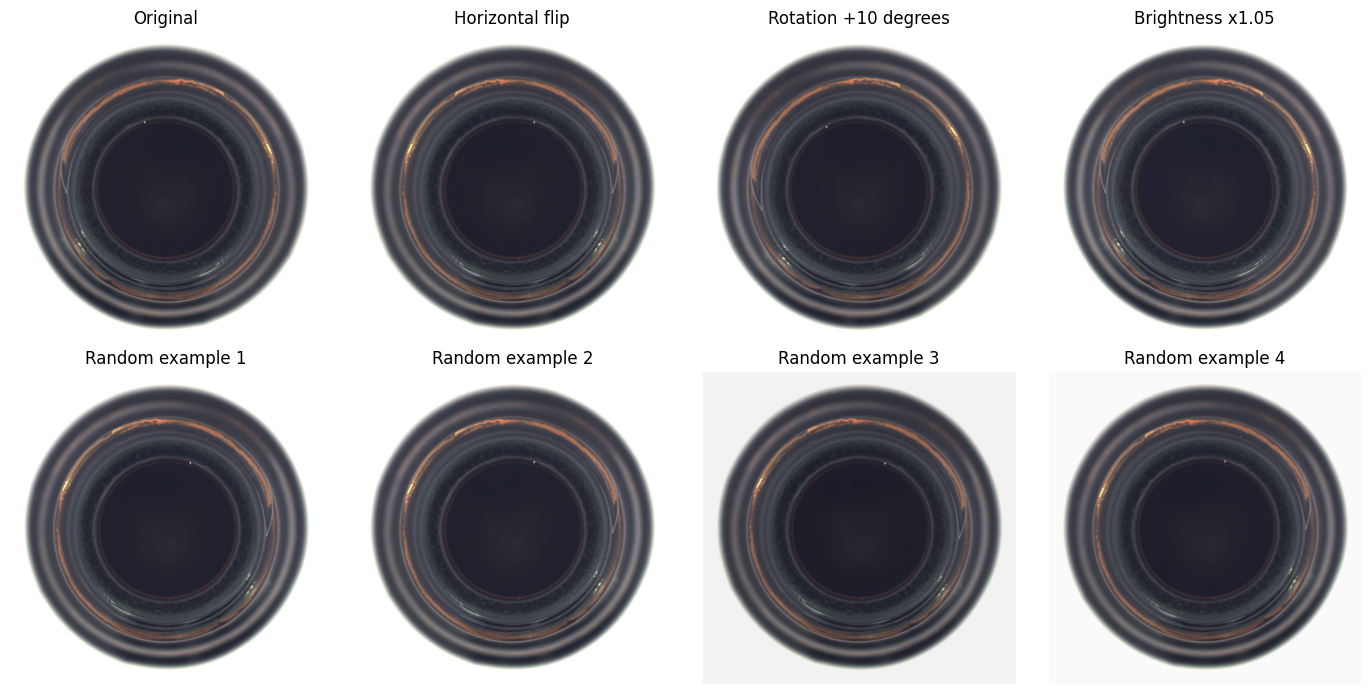

Training example: 037.png
Augmentation settings: {'enabled': True, 'seed': 42, 'horizontal_flip_probability': 0.5, 'rotation_probability': 0.5, 'max_rotation_degrees': 10.0, 'brightness_probability': 0.5, 'brightness_min': 0.95, 'brightness_max': 1.05}


In [42]:
import subprocess
from pathlib import Path

repo = Path(STUDENT_REPO)
expected = repo / "P2" / "trn_img_augmentation.py"

branch = subprocess.check_output(
    ["git", "-C", str(repo), "branch", "--show-current"],
    text=True
).strip()

commit = subprocess.check_output(
    ["git", "-C", str(repo), "rev-parse", "--short", "HEAD"],
    text=True
).strip()

tracked_files = subprocess.check_output(
    ["git", "-C", str(repo), "ls-tree", "-r", "--name-only", "HEAD"],
    text=True
).splitlines()

print("Branch:", branch)
print("Commit:", commit)
print("Expected path:", expected)
print("File exists:", expected.is_file())
print(
    "Tracked files containing 'augment':",
    [name for name in tracked_files if "augment" in name.lower()]
)
import importlib.util
import subprocess
from pathlib import Path

# Stage 3 defines the repository path and branch.
if "STUDENT_REPO" not in globals() or "STUDENT_BRANCH" not in globals():
    raise RuntimeError(
        "Run Stage 3 first to set STUDENT_REPO and STUDENT_BRANCH."
    )

# Stage 4 creates the training-image list.
if "train_paths" not in globals() or len(train_paths) == 0:
    raise RuntimeError(
        "Run Stage 4 first to prepare the training images."
    )

# Update the existing checkout from your branch.
subprocess.run(
    [
        "git", "-C", str(STUDENT_REPO),
        "pull", "--ff-only", "origin", STUDENT_BRANCH
    ],
    check=True
)

AUGMENTATION_FILE = (
    Path(STUDENT_REPO) / "P2" / "trn_img_augmentation.py"
)

if not AUGMENTATION_FILE.is_file():
    raise FileNotFoundError(
        f"Augmentation file not found: {AUGMENTATION_FILE}\n"
        "Add the corrected trn_img_augmentation.py to P2 "
        "and push it to your branch."
    )

# Load the separate Python file.
spec = importlib.util.spec_from_file_location(
    "trn_img_augmentation", AUGMENTATION_FILE
)

if spec is None or spec.loader is None:
    raise ImportError(
        f"Cannot load augmentation file: {AUGMENTATION_FILE}"
    )

augmentation_module = importlib.util.module_from_spec(spec)

try:
    spec.loader.exec_module(augmentation_module)
except NameError as exc:
    raise RuntimeError(
        f"Could not import {AUGMENTATION_FILE}: {exc}\n"
        "Check that this is the corrected file with the preview "
        "inside a function."
    ) from exc

# Check that the file provides everything the notebook needs.
required_names = (
    "AUGMENT_CONFIG",
    "augmentation_rng",
    "augment_normal_image",
    "preview_augmentation",
)

missing = [
    name for name in required_names
    if not hasattr(augmentation_module, name)
]

if missing:
    raise AttributeError(
        f"Augmentation file is missing: {', '.join(missing)}"
    )

# Make these available to the training cells.
AUGMENT_CONFIG = augmentation_module.AUGMENT_CONFIG
augmentation_rng = augmentation_module.augmentation_rng
augment_normal_image = augmentation_module.augment_normal_image
preview_augmentation = augmentation_module.preview_augmentation

print("Augmentation loaded from:", AUGMENTATION_FILE)

# Display examples using one normal training image.
preview_augmentation(train_paths[0])


---
## Stage 5 - takes one training image, calculates the loss, and makes one update to the student

In [43]:
# Put the student in training mode
student_model.train()

# Load one image from the training split
with Image.open(train_paths[0]) as image:
    training_image = augment_normal_image(image, augmentation_rng)

# The teacher returns both the preprocessed image and its features.
teacher_pixels, teacher_features = teacher.extract(training_image)

# Clear old student gradients
optimizer.zero_grad(set_to_none=True)

# Student processes the same preprocessed image
student_features = student_model(teacher_pixels)

assert student_features.shape == teacher_features.shape

# Normalize each 384-element feature vector
student_unit = F.normalize(student_features, p=2, dim=1)
teacher_unit = F.normalize(teacher_features, p=2, dim=1)

# Calculate the feature-matching loss
loss = F.mse_loss(student_unit, teacher_unit)

# Save one student layer's weights so we can see the update
first_parameter = next(student_model.parameters())
weights_before = first_parameter.detach().clone()

# Calculate gradients and update the student
loss.backward()

gradient_norm = first_parameter.grad.norm().item()

optimizer.step()

weight_change = (
    first_parameter.detach() - weights_before
).abs().max().item()

print("Teacher features:", tuple(teacher_features.shape))
print("Student features:", tuple(student_features.shape))
print("Loss before correction:", loss.item())
print("Student gradient norm:", gradient_norm)
print("Largest change in first layer:", weight_change)


Teacher features: (1, 384, 14, 14)
Student features: (1, 384, 14, 14)
Loss before correction: 0.005267200525850058
Student gradient norm: 0.0009639699128456414
Largest change in first layer: 0.0009998846799135208


---
## Stage 6 - Repeat over all training images
167 training images, measures loss on the 42 development images, and saves the checkpoint with the lowest development loss.

In [ ]:
from datetime import datetime
from torch.utils.data import DataLoader

BATCH_SIZE = 4
EPOCHS = 10  # Starting value; adjust based on development results

train_loader = DataLoader(
    [str(path) for path in train_paths],
    batch_size=BATCH_SIZE,
    shuffle=True
)

dev_loader = DataLoader(
    [str(path) for path in dev_paths],
    batch_size=BATCH_SIZE,
    shuffle=False
)


def load_images(paths):
    """Open a batch of files as RGB PIL images."""
    images = []

    for path in paths:
        with Image.open(path) as image:
            images.append(image.convert("RGB"))

    return images


def feature_matching_loss(student_features, teacher_features):
    """MSE between L2-normalized patch feature vectors."""
    if student_features.shape != teacher_features.shape:
        raise ValueError(
            "Student and teacher feature shapes do not match."
        )

    student_unit = F.normalize(student_features, p=2, dim=1)
    teacher_unit = F.normalize(teacher_features, p=2, dim=1)

    return F.mse_loss(student_unit, teacher_unit)


def run_epoch(loader, training):
    """Train for one epoch or calculate development loss."""
    student_model.train(training)

    total_loss = 0.0
    total_images = 0

    for batch_paths in loader:
        images = load_images(batch_paths)

        # teacher.extract() uses the frozen teacher
        teacher_pixels, teacher_features = teacher.extract(images)

        if training:
            optimizer.zero_grad(set_to_none=True)

        # Gradients are enabled only for the training pass
        with torch.set_grad_enabled(training):
            student_features = student_model(teacher_pixels)

            loss = feature_matching_loss(
                student_features,
                teacher_features
            )

            if not torch.isfinite(loss).item():
                raise ValueError("Loss is not finite.")

            if training:
                loss.backward()
                optimizer.step()

        batch_size = len(images)
        total_loss += loss.item() * batch_size
        total_images += batch_size

    return total_loss / total_images


# Save the best student checkpoint on Google Drive
drive_root = Path("/content/drive/MyDrive")

if not drive_root.is_dir():
    raise RuntimeError("Mount Google Drive before saving the checkpoint.")

checkpoint_dir = drive_root / "ANOMAFORGE" / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

run_time = datetime.now().strftime("%Y%m%d_%H%M%S")
checkpoint_path = checkpoint_dir / f"student_best_{run_time}.pt"

best_dev_loss = float("inf")
train_history = []
dev_history = []

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    dev_loss = run_epoch(dev_loader, training=False)

    train_history.append(train_loss)
    dev_history.append(dev_loss)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss: {train_loss:.6f} | "
        f"development loss: {dev_loss:.6f}"
    )

    # Keep the student with the lowest development loss
    if dev_loss < best_dev_loss:
        best_dev_loss = dev_loss

        torch.save(
            {
                "model_state_dict": student_model.state_dict(),
                "epoch": epoch,
                "dev_loss": dev_loss,
                "train_files": [path.name for path in train_paths],
                "dev_files": [path.name for path in dev_paths],
            },
            checkpoint_path
        )

        print("  Saved best student checkpoint.")

print("Best checkpoint:", checkpoint_path)

checkpoint = torch.load(
    checkpoint_path,
    map_location=teacher.device,
    weights_only=True
)

student_model.load_state_dict(checkpoint["model_state_dict"])
student_model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print("Development loss:", checkpoint["dev_loss"])

---
## Stage 6B - Plot the two losses

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_history) + 1)

plt.plot(epochs, train_history, label="Training")
plt.plot(epochs, dev_history, label="Development")

plt.xlabel("Epoch")
plt.ylabel("Normalized feature MSE")
plt.legend()
plt.grid(True)
plt.show()

---
## Stage 7 - Calculate an anomaly map and image score

In [ ]:
import math
import torch.nn.functional as F


@torch.no_grad()
def anomaly_score(image):
    """
    Return:
      1. A 224 x 224 teacher-student discrepancy map
      2. An image score: mean of the highest-scoring 1% of pixels
    """

    # Teacher preprocesses the image and extracts its features
    teacher_pixels, teacher_features = teacher.extract(
        image.convert("RGB")
    )

    # Student receives the same preprocessed image
    student_features = student_model(teacher_pixels)

    if teacher_features.shape != student_features.shape:
        raise ValueError("Teacher and student feature shapes do not match.")

    # Compare the 384-element feature vectors at each grid position.
    # Shape: [1, 14, 14]
    patch_map = 1 - F.cosine_similarity(
        teacher_features,
        student_features,
        dim=1
    )

    # Resize to the processed image size: [1, 1, 224, 224]
    image_map = F.interpolate(
        patch_map.unsqueeze(1),
        size=teacher_pixels.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    # Average the highest-scoring 1% of pixels
    flattened = image_map.flatten()
    k = max(1, math.ceil(0.01 * flattened.numel()))

    score = torch.topk(flattened, k).values.mean().item()

    return image_map[0, 0].cpu(), score

Set the threshold using normal development images

In [ ]:
from PIL import Image

dev_paths_for_scoring = [
    Path(BOTTLE_DIR) / "train" / "good" / name
    for name in checkpoint["dev_files"]
]

dev_scores = []

for path in dev_paths_for_scoring:
    with Image.open(path) as image:
        _, score = anomaly_score(image)

    dev_scores.append(score)

threshold = torch.quantile(
    torch.tensor(dev_scores, dtype=torch.float32),
    0.95
).item()

print("Normal development images:", len(dev_scores))
print("Anomaly threshold:", threshold)

In [ ]:
import matplotlib.pyplot as plt

with Image.open(defect_path) as image:
    heatmap, score = anomaly_score(image)

prediction = "REVIEW — possible defect" if score > threshold else "PASS"

print("Image:", defect_path.name)
print("Anomaly score:", score)
print("Threshold:", threshold)
print("Prediction:", prediction)

plt.imshow(heatmap, cmap="inferno")
plt.colorbar(label="Teacher–student discrepancy")
plt.title("Anomaly heatmap")
plt.axis("off")
plt.show()